# HelpNow | Classificação Inteligente de Chamados
**Projeto de Machine Learning e Deep Learning**

Objetivo: classificar mensagens de atendimento em **Alta, Média ou Baixa urgência** usando texto.

**Importante:** como não foi fornecida uma base oficial, o notebook usa exemplos fictícios. As métricas servem para demonstrar o fluxo técnico e **não representam o desempenho real da HelpNow**. Não afirmar redução de 40% no tempo sem um teste real.

## 1. Bibliotecas
Execute as células de cima para baixo. No Google Colab, TensorFlow e scikit-learn geralmente já estão disponíveis. Se o XGBoost não estiver instalado, a célula seguinte tenta instalá-lo.

Base demonstrativa carregada!
Total de chamados: 60

Distribuição das prioridades:
prioridade
Alta     20
Média    20
Baixa    20
Name: count, dtype: int64

Classes identificadas: ['Alta', 'Baixa', 'Média']

Exemplo de texto tratado:
                                           texto  \
0                  servidor principal fora do ar   
1  sistema da empresa completamente indisponível   
2          ataque de segurança detectado na rede   
3                vazamento de dados dos clientes   
4    todos os computadores sem acesso ao sistema   

                                     texto_limpo prioridade  
0                  servidor principal fora do ar       Alta  
1  sistema da empresa completamente indisponível       Alta  
2          ataque de segurança detectado na rede       Alta  
3                vazamento de dados dos clientes       Alta  
4    todos os computadores sem acesso ao sistema       Alta  

Treinamento: 45 chamados
Teste: 15 chamados

Treinando SVM linear...
Accuracy: 0

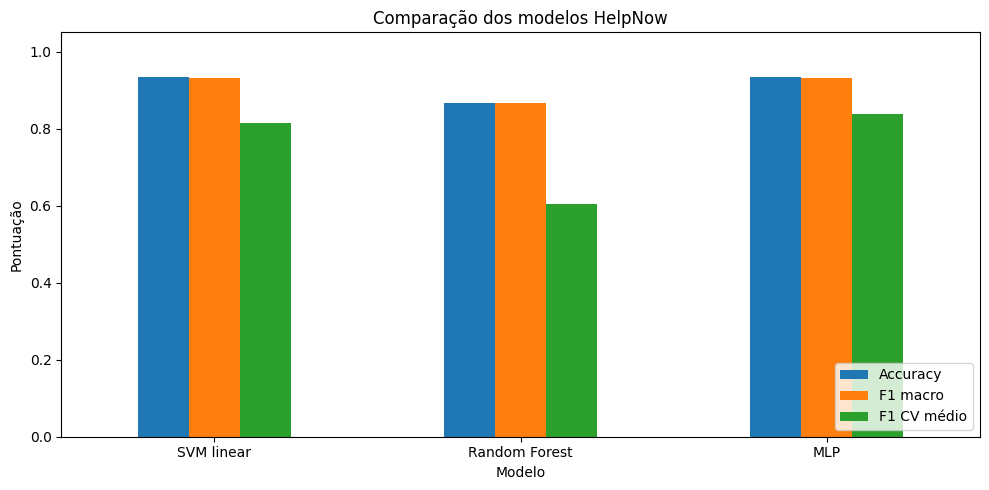


Melhor modelo pelo F1 macro: SVM linear

===== RELATÓRIO DE CLASSIFICAÇÃO =====
              precision    recall  f1-score   support

        Alta       1.00      0.80      0.89         5
       Baixa       1.00      1.00      1.00         5
       Média       0.83      1.00      0.91         5

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15



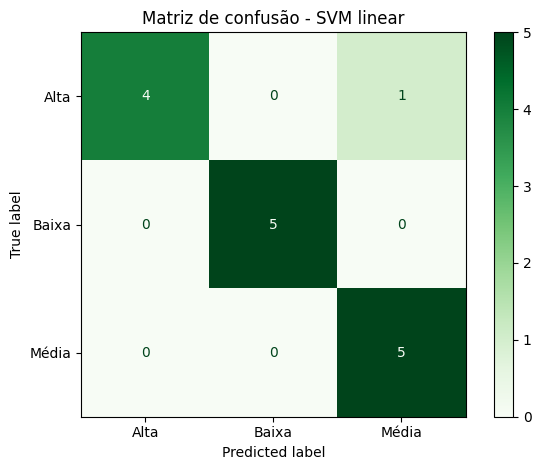


AUC macro: 0.9933


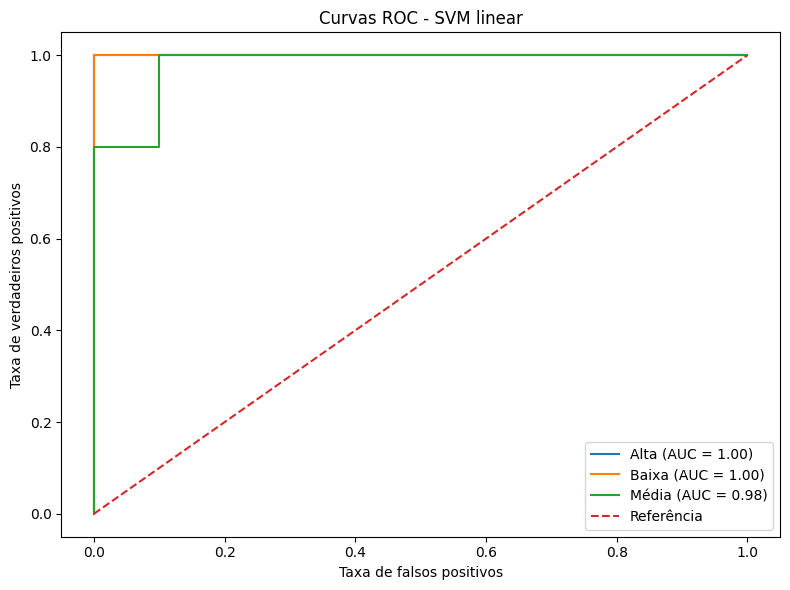


===== ANÁLISE DE OVERFITTING =====

Modelo: SVM linear
Accuracy no treino: 1.0000
Accuracy no teste: 0.9333
Diferença: 0.0667
Não há sinal forte de overfitting por essa diferença.

Modelo: Random Forest
Accuracy no treino: 1.0000
Accuracy no teste: 0.8667
Diferença: 0.1333
Não há sinal forte de overfitting por essa diferença.

Modelo: MLP
Accuracy no treino: 1.0000
Accuracy no teste: 0.9333
Diferença: 0.0667
Não há sinal forte de overfitting por essa diferença.


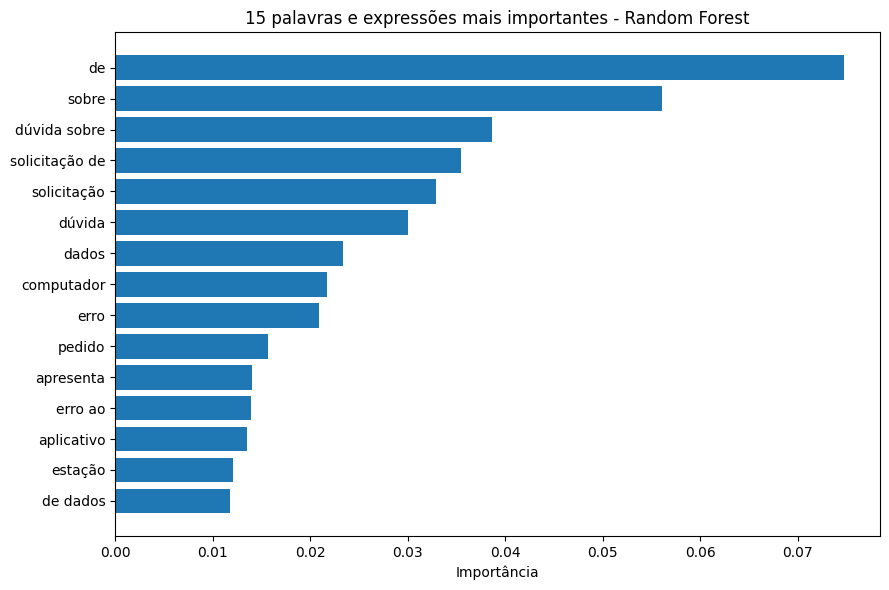


===== TESTE DE NOVO CHAMADO =====
Chamado: servidor principal está fora do ar
Prioridade prevista: Alta

Probabilidades por prioridade:
Alta: 99.67%
Baixa: 0.03%
Média: 0.30%

Fim da execução do projeto HelpNow!


In [5]:


# ============================================================
# PROJETO HELPNOW - CLASSIFICAÇÃO DE CHAMADOS COM MACHINE LEARNING
# ============================================================

import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

# ============================================================
# 1. BASE DEMONSTRATIVA DE CHAMADOS
# ============================================================

dados = {
    "texto": [
        # Alta prioridade
        "servidor principal fora do ar",
        "sistema da empresa completamente indisponível",
        "ataque de segurança detectado na rede",
        "vazamento de dados dos clientes",
        "todos os computadores sem acesso ao sistema",
        "banco de dados principal parou de funcionar",
        "sistema financeiro indisponível para todos",
        "falha crítica na infraestrutura de TI",
        "rede corporativa totalmente indisponível",
        "risco de perda de dados importantes",
        "aplicação principal apresenta erro crítico",
        "serviço essencial da empresa está parado",
        "suspeita de invasão no servidor",
        "sistema de vendas fora do ar",
        "falha geral de autenticação dos usuários",
        "servidor apresenta falha crítica",
        "dados corporativos inacessíveis",
        "incidente grave de segurança digital",
        "interrupção total dos serviços de TI",
        "sistema principal não inicia",

        # Média prioridade
        "computador de um funcionário está lento",
        "impressora do setor não funciona",
        "erro ao acessar o sistema de relatórios",
        "programa apresenta falhas ocasionais",
        "problema para instalar um aplicativo",
        "internet instável em uma estação",
        "erro ao abrir arquivos compartilhados",
        "solicitação de atualização de software",
        "problema no acesso de um usuário",
        "computador reinicia inesperadamente",
        "aplicativo apresenta lentidão",
        "falha na conexão de uma estação",
        "erro ao gerar relatório mensal",
        "solicitação de configuração de computador",
        "impressora apresenta erro de conexão",
        "sistema apresenta lentidão para um usuário",
        "problema com atualização do programa",
        "falha ao acessar pasta compartilhada",
        "computador apresenta erro de inicialização",
        "dificuldade para conectar ao wifi",

        # Baixa prioridade
        "solicitação de instalação de papel de parede",
        "dúvida sobre como alterar a senha",
        "pedido de criação de atalho na área de trabalho",
        "solicitação de manual do sistema",
        "dúvida sobre utilização de aplicativo",
        "pedido de orientação sobre impressora",
        "solicitação de troca de papel de parede",
        "dúvida sobre configuração de assinatura de email",
        "pedido de tutorial para utilizar o sistema",
        "solicitação de informação sobre software",
        "dúvida sobre atalhos do teclado",
        "pedido de orientação para organizar arquivos",
        "solicitação de ajuda com formatação de texto",
        "dúvida sobre funcionamento de recurso do sistema",
        "pedido de instruções para configurar email",
        "solicitação de material de treinamento",
        "dúvida sobre uso de ferramenta de escritório",
        "pedido de orientação básica de informática",
        "solicitação de explicação sobre funcionalidade",
        "dúvida sobre como personalizar o computador"
    ],
    "prioridade": (
        ["Alta"] * 20 +
        ["Média"] * 20 +
        ["Baixa"] * 20
    )
}

df = pd.DataFrame(dados)

print("Base demonstrativa carregada!")
print("Total de chamados:", len(df))
print("\nDistribuição das prioridades:")
print(df["prioridade"].value_counts())

# ============================================================
# 2. PRÉ-PROCESSAMENTO DOS TEXTOS
# ============================================================

def limpar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-záàâãéèêíïóôõöúçñ\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df["texto_limpo"] = df["texto"].apply(limpar_texto)

X = df["texto_limpo"]
y = df["prioridade"]

# Codificação das classes
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

classes = encoder.classes_

print("\nClasses identificadas:", list(classes))
print("\nExemplo de texto tratado:")
print(df[["texto", "texto_limpo", "prioridade"]].head())

# ============================================================
# 3. SEPARAÇÃO ENTRE TREINO E TESTE
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("\nTreinamento:", len(X_train), "chamados")
print("Teste:", len(X_test), "chamados")

# ============================================================
# 4. TF-IDF E MODELOS DE MACHINE LEARNING
# ============================================================

modelos = {
    "SVM linear": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("modelo", SVC(
            kernel="linear",
            probability=True,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("modelo", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "MLP": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("modelo", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=500,
            random_state=42,
            early_stopping=False
        ))
    ])
}

resultados = []
modelos_treinados = {}

for nome, modelo in modelos.items():
    print(f"\nTreinando {nome}...")

    modelo.fit(X_train, y_train)

    predicoes = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)

    accuracy = accuracy_score(y_test, predicoes)
    f1 = f1_score(
        y_test,
        predicoes,
        average="macro",
        zero_division=0
    )

    # Validação cruzada usando apenas os dados de treino
    cv_scores = cross_val_score(
        clone(modelo),
        X_train,
        y_train,
        cv=3,
        scoring="f1_macro"
    )

    resultados.append({
        "Modelo": nome,
        "Accuracy": accuracy,
        "F1 macro": f1,
        "F1 CV médio": cv_scores.mean()
    })

    modelos_treinados[nome] = modelo

    print("Accuracy:", round(accuracy, 4))
    print("F1 macro:", round(f1, 4))
    print("F1 médio na validação cruzada:", round(cv_scores.mean(), 4))

# ============================================================
# 5. RESULTADOS COMPARATIVOS
# ============================================================

resultados_df = pd.DataFrame(resultados)

print("\n===== COMPARAÇÃO DOS MODELOS =====")
print(resultados_df.round(4).to_string(index=False))

# Gráfico comparativo
resultados_df.set_index("Modelo")[[
    "Accuracy", "F1 macro", "F1 CV médio"
]].plot(kind="bar", figsize=(10, 5))

plt.title("Comparação dos modelos HelpNow")
plt.ylabel("Pontuação")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ============================================================
# 6. RELATÓRIO DE CLASSIFICAÇÃO
# ============================================================

melhor_nome = resultados_df.loc[
    resultados_df["F1 macro"].idxmax(), "Modelo"
]

melhor_modelo = modelos_treinados[melhor_nome]
y_pred = melhor_modelo.predict(X_test)
y_prob = melhor_modelo.predict_proba(X_test)

print("\nMelhor modelo pelo F1 macro:", melhor_nome)

print("\n===== RELATÓRIO DE CLASSIFICAÇÃO =====")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

# ============================================================
# 7. MATRIZ DE CONFUSÃO
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(cmap="Greens", values_format="d")
plt.title(f"Matriz de confusão - {melhor_nome}")
plt.tight_layout()
plt.show()

# ============================================================
# 8. CURVAS ROC E AUC MULTICLASSE
# ============================================================

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(classes))
)

auc_macro = roc_auc_score(
    y_test_bin,
    y_prob,
    average="macro",
    multi_class="ovr"
)

print("\nAUC macro:", round(auc_macro, 4))

plt.figure(figsize=(8, 6))

for i, classe in enumerate(classes):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    auc_classe = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{classe} (AUC = {auc_classe:.2f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Referência")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title(f"Curvas ROC - {melhor_nome}")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 9. ANÁLISE DE OVERFITTING
# ============================================================

print("\n===== ANÁLISE DE OVERFITTING =====")

for nome, modelo in modelos_treinados.items():
    score_treino = modelo.score(X_train, y_train)
    score_teste = modelo.score(X_test, y_test)
    diferenca = score_treino - score_teste

    print(f"\nModelo: {nome}")
    print(f"Accuracy no treino: {score_treino:.4f}")
    print(f"Accuracy no teste: {score_teste:.4f}")
    print(f"Diferença: {diferenca:.4f}")

    if diferenca > 0.15:
        print("Atenção: possível overfitting.")
    else:
        print("Não há sinal forte de overfitting por essa diferença.")

# ============================================================
# 10. IMPORTÂNCIA DAS PALAVRAS
# ============================================================

rf = modelos_treinados["Random Forest"]

vetorizador = rf.named_steps["tfidf"]
classificador = rf.named_steps["modelo"]

importancias = classificador.feature_importances_
palavras = vetorizador.get_feature_names_out()

top_indices = np.argsort(importancias)[-15:]

plt.figure(figsize=(9, 6))
plt.barh(
    palavras[top_indices],
    importancias[top_indices]
)

plt.title("15 palavras e expressões mais importantes - Random Forest")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()

# ============================================================
# 11. TESTAR UM NOVO CHAMADO
# ============================================================

novo_chamado = "servidor principal está fora do ar"

novo_chamado_limpo = limpar_texto(novo_chamado)

previsao = melhor_modelo.predict([novo_chamado_limpo])
probabilidades = melhor_modelo.predict_proba([novo_chamado_limpo])[0]

print("\n===== TESTE DE NOVO CHAMADO =====")
print("Chamado:", novo_chamado)
print("Prioridade prevista:", encoder.inverse_transform(previsao)[0])

print("\nProbabilidades por prioridade:")
for classe, prob in zip(classes, probabilidades):
    print(f"{classe}: {prob:.2%}")

print("\nFim da execução do projeto HelpNow!")


In [6]:

# ==================================================
# HELPNOW - MACHINE LEARNING
# CÉLULA 1: IMPORTAÇÕES E BASE DE DADOS
# ==================================================

import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

# Base demonstrativa de chamados
dados = {
    "texto": [
        "servidor principal fora do ar",
        "sistema da empresa completamente indisponível",
        "ataque de segurança detectado na rede",
        "vazamento de dados dos clientes",
        "todos os computadores sem acesso ao sistema",
        "banco de dados principal parou de funcionar",
        "sistema financeiro indisponível para todos",
        "falha crítica na infraestrutura de TI",
        "rede corporativa totalmente indisponível",
        "risco de perda de dados importantes",
        "aplicação principal apresenta erro crítico",
        "serviço essencial da empresa está parado",
        "suspeita de invasão no servidor",
        "sistema de vendas fora do ar",
        "falha geral de autenticação dos usuários",
        "servidor apresenta falha crítica",
        "dados corporativos inacessíveis",
        "incidente grave de segurança digital",
        "interrupção total dos serviços de TI",
        "sistema principal não inicia",

        "computador de um funcionário está lento",
        "impressora do setor não funciona",
        "erro ao acessar o sistema de relatórios",
        "programa apresenta falhas ocasionais",
        "problema para instalar um aplicativo",
        "internet instável em uma estação",
        "erro ao abrir arquivos compartilhados",
        "solicitação de atualização de software",
        "problema no acesso de um usuário",
        "computador reinicia inesperadamente",
        "aplicativo apresenta lentidão",
        "falha na conexão de uma estação",
        "erro ao gerar relatório mensal",
        "solicitação de configuração de computador",
        "impressora apresenta erro de conexão",
        "sistema apresenta lentidão para um usuário",
        "problema com atualização do programa",
        "falha ao acessar pasta compartilhada",
        "computador apresenta erro de inicialização",
        "dificuldade para conectar ao wifi",

        "solicitação de instalação de papel de parede",
        "dúvida sobre como alterar a senha",
        "pedido de criação de atalho na área de trabalho",
        "solicitação de manual do sistema",
        "dúvida sobre utilização de aplicativo",
        "pedido de orientação sobre impressora",
        "solicitação de troca de papel de parede",
        "dúvida sobre configuração de assinatura de email",
        "pedido de tutorial para utilizar o sistema",
        "solicitação de informação sobre software",
        "dúvida sobre atalhos do teclado",
        "pedido de orientação para organizar arquivos",
        "solicitação de ajuda com formatação de texto",
        "dúvida sobre funcionamento de recurso do sistema",
        "pedido de instruções para configurar email",
        "solicitação de material de treinamento",
        "dúvida sobre uso de ferramenta de escritório",
        "pedido de orientação básica de informática",
        "solicitação de explicação sobre funcionalidade",
        "dúvida sobre como personalizar o computador"
    ],
    "prioridade": (
        ["Alta"] * 20 +
        ["Média"] * 20 +
        ["Baixa"] * 20
    )
}

df = pd.DataFrame(dados)

print("Base carregada com sucesso!")
print("Total de chamados:", len(df))
print("\nDistribuição das prioridades:")
print(df["prioridade"].value_counts())


Base carregada com sucesso!
Total de chamados: 60

Distribuição das prioridades:
prioridade
Alta     20
Média    20
Baixa    20
Name: count, dtype: int64


In [7]:

# ==================================================
# CÉLULA 2: PRÉ-PROCESSAMENTO DOS DADOS
# ==================================================

# Função para limpar os textos dos chamados
def limpar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r"http\S+|www\S+", " ", texto)
    texto = re.sub(r"[^a-záàâãéèêíïóôõöúçñ\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

# Aplicar a limpeza na base
df["texto_limpo"] = df["texto"].apply(limpar_texto)

# Separar os textos e as respectivas prioridades
X = df["texto_limpo"]
y = df["prioridade"]

# Transformar as categorias em números
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Separar os dados para treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.25,
    random_state=42,
    stratify=y_encoded
)

print("Pré-processamento concluído!")
print("Classes:", list(encoder.classes_))
print("Dados de treinamento:", len(X_train))
print("Dados de teste:", len(X_test))

# Conferir exemplos
display(df[["texto", "texto_limpo", "prioridade"]].head())


Pré-processamento concluído!
Classes: ['Alta', 'Baixa', 'Média']
Dados de treinamento: 45
Dados de teste: 15


,texto,texto_limpo,prioridade
0,servidor principal fora do ar,servidor principal fora do ar,Alta
1,sistema da empresa completamente indisponível,sistema da empresa completamente indisponível,Alta
2,ataque de segurança detectado na rede,ataque de segurança detectado na rede,Alta
3,vazamento de dados dos clientes,vazamento de dados dos clientes,Alta
4,todos os computadores sem acesso ao sistema,todos os computadores sem acesso ao sistema,Alta


In [8]:

# ==================================================
# CÉLULA 3: TREINAMENTO DOS MODELOS
# ==================================================

# Modelo 1: SVM linear
modelo_svm = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("modelo", SVC(
        kernel="linear",
        probability=True,
        random_state=42
    ))
])

# Modelo 2: Random Forest
modelo_rf = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Modelo 3: MLP
modelo_mlp = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("modelo", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500,
        random_state=42
    ))
])

# Organizar os modelos
modelos = {
    "SVM linear": modelo_svm,
    "Random Forest": modelo_rf,
    "MLP": modelo_mlp
}

# Treinar e guardar as previsões
modelos_treinados = {}
resultados_modelos = {}

for nome, modelo in modelos.items():
    print(f"Treinando {nome}...")

    modelo.fit(X_train, y_train)

    previsoes = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)

    modelos_treinados[nome] = modelo

    resultados_modelos[nome] = {
        "previsoes": previsoes,
        "probabilidades": probabilidades,
        "accuracy": accuracy_score(y_test, previsoes),
        "f1_macro": f1_score(
            y_test,
            previsoes,
            average="macro",
            zero_division=0
        )
    }

print("\nTreinamento concluído!")
print("Modelos treinados:", list(modelos_treinados.keys()))


Treinando SVM linear...
Treinando Random Forest...
Treinando MLP...

Treinamento concluído!
Modelos treinados: ['SVM linear', 'Random Forest', 'MLP']


COMPARAÇÃO DOS MODELOS


,Modelo,Accuracy,F1 macro
0,SVM linear,0.9333,0.9327
1,Random Forest,0.8667,0.8667
2,MLP,0.9333,0.9327


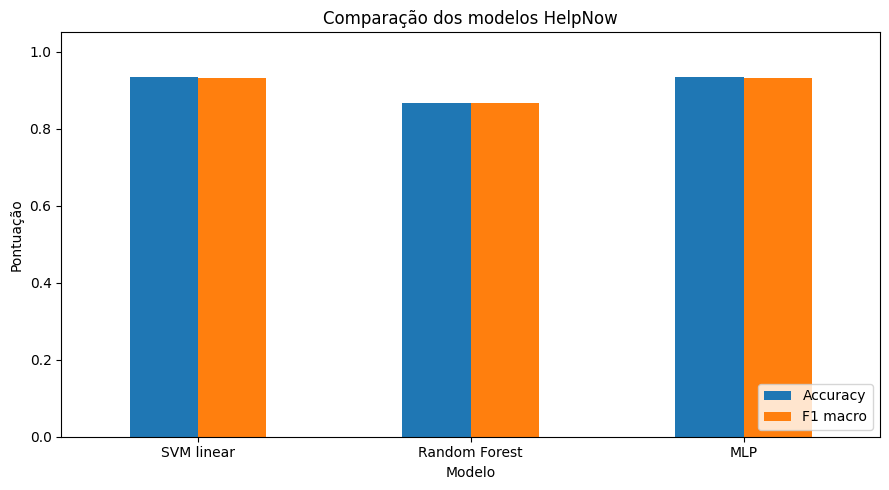

In [9]:

# ==================================================
# CÉLULA 4: COMPARAÇÃO DOS MODELOS
# ==================================================

resultados = []

for nome, resultado in resultados_modelos.items():
    resultados.append({
        "Modelo": nome,
        "Accuracy": resultado["accuracy"],
        "F1 macro": resultado["f1_macro"]
    })

resultados_df = pd.DataFrame(resultados)

print("COMPARAÇÃO DOS MODELOS")
display(resultados_df.round(4))

# Gráfico comparativo
resultados_df.set_index("Modelo").plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Comparação dos modelos HelpNow")
plt.ylabel("Pontuação")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Modelo selecionado: SVM linear


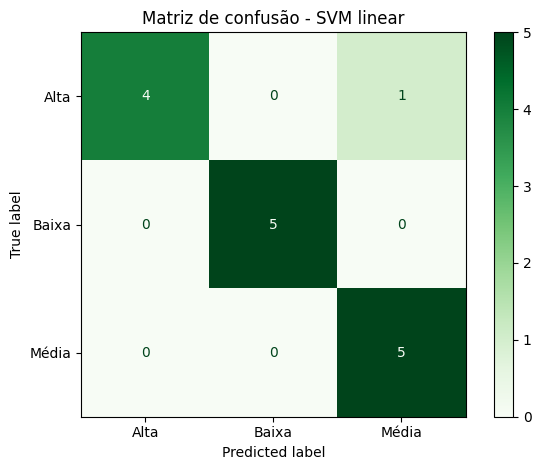


RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alta       1.00      0.80      0.89         5
       Baixa       1.00      1.00      1.00         5
       Média       0.83      1.00      0.91         5

    accuracy                           0.93        15
   macro avg       0.94      0.93      0.93        15
weighted avg       0.94      0.93      0.93        15



In [10]:

# ==================================================
# CÉLULA 5: MATRIZ DE CONFUSÃO
# ==================================================

# Selecionar o melhor modelo pelo F1 macro
melhor_nome = max(
    resultados_modelos,
    key=lambda nome: resultados_modelos[nome]["f1_macro"]
)

melhor_modelo = modelos_treinados[melhor_nome]
y_pred = resultados_modelos[melhor_nome]["previsoes"]

print("Modelo selecionado:", melhor_nome)

# Gerar matriz de confusão
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(cmap="Greens", values_format="d")
plt.title(f"Matriz de confusão - {melhor_nome}")
plt.tight_layout()
plt.show()

# Relatório detalhado
print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))


Modelo avaliado: SVM linear
AUC macro: 0.9933


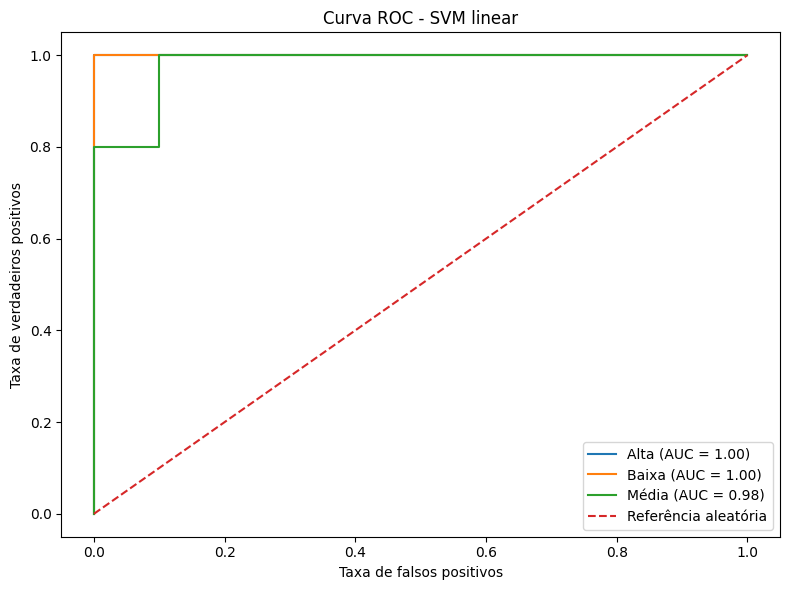

In [11]:

# ==================================================
# CÉLULA 6: CURVA ROC E AUC
# ==================================================

# Obter probabilidades do melhor modelo
y_prob = resultados_modelos[melhor_nome]["probabilidades"]

# Converter as classes para formato binário
y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(encoder.classes_))
)

# Calcular AUC para classificação multiclasse
auc_macro = roc_auc_score(
    y_test_bin,
    y_prob,
    average="macro"
)

print(f"Modelo avaliado: {melhor_nome}")
print(f"AUC macro: {auc_macro:.4f}")

# Desenhar uma curva ROC para cada classe
plt.figure(figsize=(8, 6))

for i, classe in enumerate(encoder.classes_):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    valor_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{classe} (AUC = {valor_auc:.2f})"
    )

# Linha de referência
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Referência aleatória"
)

plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.title(f"Curva ROC - {melhor_nome}")
plt.legend()
plt.tight_layout()
plt.show()


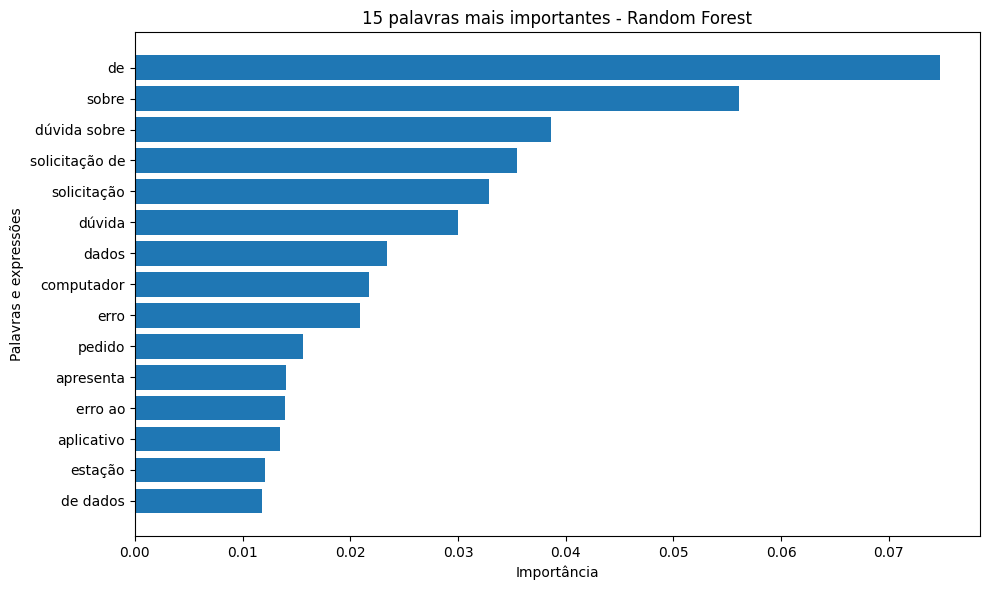

Visualização de importância concluída!


In [12]:

# ==================================================
# CÉLULA 7: IMPORTÂNCIA DAS PALAVRAS
# ==================================================

# Recuperar o Random Forest treinado
modelo_rf_treinado = modelos_treinados["Random Forest"]

vetorizador = modelo_rf_treinado.named_steps["tfidf"]
classificador = modelo_rf_treinado.named_steps["modelo"]

# Obter palavras e respectivas importâncias
palavras = vetorizador.get_feature_names_out()
importancias = classificador.feature_importances_

# Selecionar as 15 palavras mais importantes
indices = np.argsort(importancias)[-15:]

plt.figure(figsize=(10, 6))

plt.barh(
    palavras[indices],
    importancias[indices]
)

plt.title("15 palavras mais importantes - Random Forest")
plt.xlabel("Importância")
plt.ylabel("Palavras e expressões")
plt.tight_layout()
plt.show()

print("Visualização de importância concluída!")


In [13]:
# CÉLULA 8: TESTAR UM NOVO CHAMADO

novo_chamado = "servidor principal está fora do ar"

novo_chamado_limpo = limpar_texto(novo_chamado)

previsao = melhor_modelo.predict([novo_chamado_limpo])

probabilidades = melhor_modelo.predict_proba([novo_chamado_limpo])[0]

print("Chamado:", novo_chamado)
print("Prioridade prevista:", encoder.inverse_transform(previsao)[0])
print("\nProbabilidades por prioridade:")

for classe, prob in zip(encoder.classes_, probabilidades):
    print(f"{classe}: {prob:.2%}")

Chamado: servidor principal está fora do ar
Prioridade prevista: Alta

Probabilidades por prioridade:
Alta: 99.67%
Baixa: 0.03%
Média: 0.30%


## Discussão crítica, limitações e melhorias

O HelpNow é um protótipo de Machine Learning desenvolvido para classificar chamados de suporte de TI em três níveis de prioridade: Alta, Média e Baixa. Foram comparados três modelos: SVM linear, Random Forest e MLP, utilizando TF-IDF para transformar os textos em representações numéricas. A avaliação foi realizada por meio de Accuracy, F1-score, matriz de confusão e curva ROC/AUC.

A principal limitação é o uso de apenas 60 exemplos simulados, que não representam necessariamente os chamados reais da empresa FecafTrade Solutions. Por isso, mesmo que os resultados sejam elevados, eles não garantem o mesmo desempenho em produção. Os dados também podem conter padrões artificiais que facilitam a classificação.

Como aspectos éticos, é importante proteger os dados dos usuários, reduzir possíveis vieses e manter a supervisão humana nas decisões de prioridade. Como melhorias futuras, recomenda-se utilizar uma base real autorizada e anonimizada, ampliar a quantidade de exemplos, validar os modelos com novos dados e monitorar continuamente os resultados.

Em produção, o HelpNow poderia auxiliar a equipe de suporte a organizar a fila de atendimento, sugerindo prioridades para análise dos profissionais responsáveis.